# Step 72 — External clock anchors from global earthquake catalogues

Every PVO data stream was time-stamped by its own PC clock. There was no GOES or GPS receiver at PVO, and the IRIG generator was free-running, so nothing recorded in 1991 ties any stream to absolute UTC. `clock_regimes.csv` fixes the hour-level offsets (Philippine time versus GMT, resets), but seconds-level errors from drift and hand-set clocks remain. The only independent absolute time available is the arrival of earthquakes whose origin times are known from global networks.

This notebook looks for such anchors without reviewing every waveform by eye:

1. **Download** ISC and USGS events for May–November 1991: within 6° of Pinatubo (M ≥ 3) and worldwide (M ≥ 6). The downloads are cached; set `DOWNLOAD=True` to refresh them.
2. **Pinatubo's own large earthquakes** in the global catalogues, compared with the local HYPO71 origins (step 43).
3. **Long S−P pick groups** (step 22): earthquakes 50–100 km away that were picked but never located.
4. **1-minute SSAM** (step 62, on the same MDETECT PC as the waveforms): a network-wide rise in the lowest bands at each predicted arrival?
5. **Triggered waveform records** (step 10) that contain the predicted P of a distant earthquake, plotted with the predicted phases for review by an analyst.

The waveforms are compared in their UTC form (step 10 clock rules), so an apparent offset is the clock error that remains after those rules. Run after steps 10, 22, 43 and 62. This notebook changes no product. It writes only to `output_root/clock_anchor_check`, and it needs network access only when `DOWNLOAD=True` or the cache is empty.

## 1. Configuration

In [1]:
from pathlib import Path
import sys, json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_candidates = [Path.cwd(), Path.cwd() / '10_conversion', *Path.cwd().parents]
PIPELINE_DIR = next((p for p in _candidates if (p / 'lib' / 'clock.py').is_file()), None)
if PIPELINE_DIR is None:
    raise FileNotFoundError('Open this notebook from the pipeline folder or project root.')
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))
from lib.config import pipeline_paths

CONFIG_FILE = None  # Default: conversion_config.json
P = pipeline_paths(config_file=CONFIG_FILE)
OUT = Path(P['OUTPUT_ROOT']) / 'clock_anchor_check'
OUT.mkdir(parents=True, exist_ok=True)

SETTINGS = dict(
    reference=(15.13, 120.35),            # Pinatubo summit (lat, lon)
    start='1991-05-01', end='1991-11-23', # waveforms May–Aug; SSAM to 22 Nov
    regional_radius_deg=6.0, regional_min_mag=3.0, global_min_mag=6.0,
    providers=('ISC', 'USGS'),
    local_max_km=80.0,                    # catalogue events treated as Pinatubo's own
    local_match_window_s=600.0,
    long_sp_min_s=6.0,                    # median S−P beyond the HYPO71-located range
    record_tolerance_s=120.0,             # predicted P within a record ± this
    ssam_stations=('CAB1', 'FNG1', 'BUG1', 'QAD1', 'PI21', 'DON1'),
    ssam_bands=('value_01', 'value_02', 'value_03'),
    ssam_ratio=2.0, ssam_baseline_min=30, ssam_window_min=4,
    plot_band_hz=(0.5, 3.0),
)
DOWNLOAD = False   # True refreshes the cached ISC/USGS downloads
print('Outputs:', OUT)

Outputs: /Users/thompsong/work/Pinatubo1991Processing/utc/clock_anchor_check


## 2. Definitions

Travel times use ObsPy TauP with iasp91. "First P" is the earliest of P, p, Pn, Pg, Pdiff and PKP. ISC and USGS entries less than 30 s and 1.5° apart are merged, keeping the ISC solution and the larger magnitude.

In [2]:
def download_catalogue(settings, path):
    from obspy import UTCDateTime
    from obspy.clients.fdsn import Client
    lat, lon = settings['reference']; rows = []; queries = []
    for provider in settings['providers']:
        client = Client(provider)
        for label, kw in [('regional', dict(latitude=lat, longitude=lon, maxradius=settings['regional_radius_deg'],
                                            minmagnitude=settings['regional_min_mag'])),
                          ('global', dict(minmagnitude=settings['global_min_mag']))]:
            query = dict(provider=provider, query=label, starttime=settings['start'], endtime=settings['end'], **kw)
            catalog = client.get_events(starttime=UTCDateTime(settings['start']), endtime=UTCDateTime(settings['end']),
                                        orderby='time-asc', **kw)
            query['events'] = len(catalog); queries.append(query)
            for event in catalog:
                origin = event.preferred_origin() or event.origins[0]
                magnitude = event.preferred_magnitude() or (event.magnitudes[0] if event.magnitudes else None)
                rows.append(dict(source=provider, query=label, time=str(origin.time), lat=origin.latitude,
                                 lon=origin.longitude, depth_km=(origin.depth or 0) / 1000,
                                 mag=magnitude.mag if magnitude else None,
                                 magtype=magnitude.magnitude_type if magnitude else None,
                                 event_id=str(event.resource_id)))
    pd.DataFrame(rows).to_csv(path, index=False)
    path.with_suffix('.json').write_text(json.dumps(dict(downloaded_utc=datetime.now(timezone.utc).isoformat(),
                                                         queries=queries), indent=2) + '\n')


def merge_catalogue(raw):
    cat = raw.copy(); cat['t'] = pd.to_datetime(cat.time, utc=True, format='mixed')
    cat = cat.sort_values(['t', 'source']).reset_index(drop=True); keep = []; used = set()
    for i, row in cat.iterrows():
        if i in used:
            continue
        same = cat[((cat.t - row.t).dt.total_seconds().abs() < 30) & ((cat.lat - row.lat).abs() < 1.5)
                   & ((cat.lon - row.lon).abs() < 1.5)]
        used |= set(same.index)
        best = same.sort_values('source', key=lambda s: s.map({'ISC': 0, 'USGS': 1})).iloc[0].copy()
        best['sources'] = '+'.join(sorted(set(same.source))); best['mag'] = same.mag.max(); keep.append(best)
    return pd.DataFrame(keep).reset_index(drop=True)


FIRST_P = ['P', 'p', 'Pn', 'Pg', 'Pdiff', 'PKP', 'PKIKP']


def add_predictions(cat, reference):
    from obspy.taup import TauPyModel
    from obspy.geodetics import locations2degrees
    model = TauPyModel('iasp91'); lat0, lon0 = reference; degrees = []; first = []
    for row in cat.itertuples():
        deg = locations2degrees(lat0, lon0, row.lat, row.lon); degrees.append(deg)
        arrivals = model.get_travel_times(source_depth_in_km=max(row.depth_km, 0), distance_in_degree=deg,
                                          phase_list=FIRST_P)
        first.append(min(a.time for a in arrivals) if arrivals else np.nan)
    out = cat.copy(); out['dist_deg'] = np.round(degrees, 2); out['dist_km'] = np.round(np.array(degrees) * 111.19)
    out['p_travel_s'] = np.round(first, 1); out['p_arrival'] = out.t + pd.to_timedelta(out.p_travel_s, unit='s')
    return out


def phase_table(event, reference, phases=('P', 'p', 'Pn', 'Pg', 'pP', 'sP', 'PcP', 'PP', 'S', 's', 'Sn', 'Sg', 'sS', 'ScS', 'SS')):
    # Phase times relative to the first P, plus surface waves at 4.0 and 3.5 km/s group velocity.
    from obspy.taup import TauPyModel
    from obspy.geodetics import locations2degrees
    deg = locations2degrees(*reference, event.lat, event.lon)
    arrivals = TauPyModel('iasp91').get_travel_times(source_depth_in_km=max(event.depth_km, 0),
                                                     distance_in_degree=deg, phase_list=list(dict.fromkeys([*phases, *FIRST_P])))
    p0 = min(a.time for a in arrivals if a.name in FIRST_P); rows = []; seen = set()
    for a in sorted(arrivals, key=lambda a: a.time):
        if a.name not in seen:
            seen.add(a.name); rows.append(dict(phase=a.name, after_first_p_s=round(a.time - p0, 1)))
    for v in (4.0, 3.5):
        rows.append(dict(phase=f'surface {v} km/s', after_first_p_s=round(deg * 111.19 / v - p0, 1)))
    return pd.DataFrame(rows)


def compare_local(cat, origins, max_km, window_s):
    o = origins.copy(); o['ot'] = pd.to_datetime(o.origin_time, utc=True, format='mixed'); rows = []
    for r in cat[cat.dist_km < max_km].itertuples():
        d = (o.ot - r.t).dt.total_seconds(); near = o[d.abs() < window_s].copy(); near['offset_s'] = d[near.index]
        row = dict(catalogue_time=r.t, mag=r.mag, dist_km=r.dist_km, sources=r.sources,
                   hypo71_within_window=len(near), hypo71_within_60s=int((near.offset_s.abs() < 60).sum()))
        if len(near):
            b = near.loc[near.offset_s.abs().idxmin()]
            row.update(nearest_hypo71=b.ot, hypo71_minus_catalogue_s=round(b.offset_s, 2), clock_regime=b.clock_regime)
        rows.append(row)
    return pd.DataFrame(rows)


def long_sp_groups(picks, min_sp):
    d = picks.copy(); d['t'] = pd.to_datetime(d.pick_time, utc=True, format='mixed')
    phase = d.phase.astype(str).str.upper().str[0]
    p = d[phase == 'P'].groupby(['event_id', 'station']).t.min()
    s = d[phase == 'S'].groupby(['event_id', 'station']).t.min()
    sp = (s - p).dropna().dt.total_seconds(); g = sp.groupby(level=0)
    ev = pd.DataFrame(dict(median_sp_s=g.median(), n_s_picks=g.size(), min_sp_s=g.min(), max_sp_s=g.max()))
    ev = ev[ev.median_sp_s > min_sp].copy()
    ev['first_p_utc'] = d[phase == 'P'].groupby('event_id').t.min().reindex(ev.index)
    ev['n_stations'] = d.groupby('event_id').station.nunique().reindex(ev.index)
    ev['approx_dist_km'] = (ev.median_sp_s * 8).round(0)
    return ev.sort_values('first_p_utc'), sp


def match_records(cat, index, tolerance_s):
    w = index.copy(); w['s'] = pd.to_datetime(w.starttime, utc=True, format='mixed')
    w['e'] = pd.to_datetime(w.endtime, utc=True, format='mixed'); w = w.dropna(subset=['s']).sort_values('s')
    tol = pd.Timedelta(seconds=tolerance_s); rows = []
    for r in cat.dropna(subset=['p_arrival']).itertuples():
        for h in w[(w.s <= r.p_arrival + tol) & (w.e >= r.p_arrival - tol)].itertuples():
            rows.append(dict(origin=r.t, mag=r.mag, lat=r.lat, lon=r.lon, dist_km=r.dist_km, depth_km=r.depth_km, sources=r.sources,
                             p_arrival=r.p_arrival, record=h.event_id, record_start=h.s, record_len_s=round((h.e - h.s).total_seconds(), 1),
                             clock_regime=h.clock_regime, predicted_p_in_record_s=round((r.p_arrival - h.s).total_seconds(), 1)))
    return pd.DataFrame(rows)


def ssam_screen(cat, records, settings, seed=0):
    x = records[records.series.isin(settings['ssam_stations'])
                & records.qc_use_for_coverage.astype(str).str.lower().eq('true')].copy()
    x['t'] = pd.to_datetime(x.recorded_time, utc=True); x['lf'] = x[list(settings['ssam_bands'])].sum(axis=1)
    pivot = x.pivot_table(index='t', columns='series', values='lf', aggfunc='first').sort_index().asfreq('1min')
    base = pivot.rolling(settings['ssam_baseline_min'], min_periods=settings['ssam_baseline_min'] // 2).median().shift(1)
    peak = (pivot / base)[::-1].rolling(settings['ssam_window_min'], min_periods=1).max()[::-1]
    rows = []
    for r in cat.dropna(subset=['p_arrival']).itertuples():
        m = r.p_arrival.floor('min')
        if m in peak.index and peak.loc[m].notna().sum() >= 3:
            v = peak.loc[m]
            rows.append(dict(origin=r.t, mag=r.mag, dist_km=r.dist_km, stations=int(v.notna().sum()),
                             median_ratio=round(v.median(), 2), max_ratio=round(v.max(), 2),
                             stations_above=int((v > settings['ssam_ratio']).sum())))
    rng = np.random.default_rng(seed); idx = peak.index[peak.notna().sum(axis=1) >= 3]
    sample = rng.choice(idx, min(5000, len(idx)), replace=False)
    random_median = np.array([peak.loc[m].median() for m in sample])
    return pd.DataFrame(rows), random_median


def plot_records(rows, index, band, reference, path=None):
    from obspy import read, UTCDateTime
    files = index.set_index('event_id')['wav_file']
    fig, axes = plt.subplots(len(rows), 1, figsize=(11, 3.3 * len(rows)), squeeze=False)
    for ax, r in zip(axes[:, 0], rows.itertuples()):
        st = read(files[r.record]); st.detrend('demean'); st.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=2)
        t0 = min(tr.stats.starttime for tr in st)
        for k, tr in enumerate(sorted(st, key=lambda t: (t.stats.station, t.stats.channel))):
            x = tr.data / (np.max(np.abs(tr.data)) + 1e-9); tt = tr.times() + (tr.stats.starttime - t0)
            ax.plot(tt, x * 0.45 + k, lw=.5, color='k'); ax.text(-1, k, tr.stats.station, ha='right', va='center', fontsize=7)
        p = UTCDateTime(pd.Timestamp(r.p_arrival).to_pydatetime()) - t0
        phases = phase_table(r, reference)
        for ph in phases.itertuples():
            x = p + ph.after_first_p_s
            if -5 < x < (st[0].stats.endtime - t0) + 5 and not ph.phase.startswith('surface'):
                ax.axvline(x, color='r' if ph.after_first_p_s == 0 else 'tab:orange', lw=1 if ph.after_first_p_s == 0 else .7)
                ax.text(x, len(st) - .3, ph.phase, color='tab:red', fontsize=7)
        ax.set_yticks([]); ax.set_xlabel('s after record start (UTC)')
        ax.set_title(f'{r.record}: {str(r.origin)[:19]} UTC, M{r.mag} at {r.dist_km:.0f} km, depth {r.depth_km:.0f} km '
                     f'[{r.clock_regime}]. Red: predicted first P; orange: later phases', fontsize=8)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=110)
    return fig

## 3. Catalogue download (cached)

In [3]:
RAW = OUT / 'catalogue_raw.csv'
if DOWNLOAD or not RAW.is_file():
    download_catalogue(SETTINGS, RAW)
print(json.loads(RAW.with_suffix('.json').read_text()))
cat = add_predictions(merge_catalogue(pd.read_csv(RAW)), SETTINGS['reference'])
cat.to_csv(OUT / 'catalogue_merged.csv', index=False)
print(len(cat), 'distinct events;', int((cat.dist_km < SETTINGS['local_max_km']).sum()), 'of them within',
      SETTINGS['local_max_km'], 'km (Pinatubo itself)')

{'downloaded_utc': '2026-11-19 (two queries, 1 May–1 Sep and 1 Sep–23 Nov 1991, concatenated)', 'queries': [{'provider': 'ISC', 'query': 'regional', 'minmagnitude': 3.0, 'maxradius_deg': 6.0}, {'provider': 'ISC', 'query': 'global', 'minmagnitude': 6.0, 'maxradius_deg': None}, {'provider': 'USGS', 'query': 'regional', 'minmagnitude': 3.0, 'maxradius_deg': 6.0}, {'provider': 'USGS', 'query': 'global', 'minmagnitude': 6.0, 'maxradius_deg': None}]}


216 distinct events; 84 of them within 80.0 km (Pinatubo itself)


## 4. Pinatubo's own large earthquakes against HYPO71

The global catalogues list many M 4–6 Pinatubo earthquakes. Pairing each with the nearest HYPO71 origin tests for minute- and hour-level errors. It cannot measure seconds: the global solutions fix depth at 10–35 km, and HYPO71 has one or two events a minute at the busiest times.

In [4]:
local = compare_local(cat, pd.read_csv(P['HYPO71_ORIGIN_INDEX']), SETTINGS['local_max_km'], SETTINGS['local_match_window_s'])
local.to_csv(OUT / 'local_catalogue_vs_hypo71.csv', index=False)
print('Catalogue events within', SETTINGS['local_max_km'], 'km:', len(local), '; with a HYPO71 origin within',
      SETTINGS['local_match_window_s'], 's:', int((local.hypo71_within_window > 0).sum()))
display(local[local.hypo71_within_window > 0])

Catalogue events within 80.0 km: 84 ; with a HYPO71 origin within 600.0 s: 15


,catalogue_time,mag,dist_km,sources,hypo71_within_window,hypo71_within_60s,nearest_hypo71,hypo71_minus_catalogue_s,clock_regime
59,1991-06-29 05:18:52.020000+00:00,4.20,30.0,USGS,5,0,1991-06-29 05:14:32.190000+00:00,-259.83,W_UTC
61,1991-07-01 05:21:54.170000+00:00,4.60,13.0,ISC+USGS,15,2,1991-07-01 05:21:43.930000+00:00,-10.24,W_UTC
62,1991-07-03 03:49:48.360000+00:00,4.70,31.0,ISC+USGS,2,2,1991-07-03 03:50:10.040000+00:00,21.68,W_UTC
63,1991-07-04 16:29:07.280000+00:00,4.60,47.0,USGS,1,1,1991-07-04 16:29:38.950000+00:00,31.67,W_UTC
66,1991-07-08 11:08:17.950000+00:00,4.70,10.0,USGS,1,0,1991-07-08 11:07:16.880000+00:00,-61.07,W_UTC
67,1991-07-09 05:33:48.400000+00:00,4.50,43.0,USGS,2,0,1991-07-09 05:40:25.290000+00:00,396.89,W_UTC
68,1991-07-09 16:27:34.340000+00:00,4.70,32.0,USGS,1,0,1991-07-09 16:26:14.910000+00:00,-79.43,W_UTC
70,1991-07-10 15:07:38.530000+00:00,4.40,16.0,ISC+USGS,2,0,1991-07-10 15:06:36.400000+00:00,-62.13,W_UTC
71,1991-07-11 16:39:59.620000+00:00,4.80,40.0,ISC+USGS,2,0,1991-07-11 16:38:55.600000+00:00,-64.02,W_UTC
72,1991-07-14 01:52:42.330000+00:00,4.70,14.0,USGS,2,0,1991-07-14 01:51:19.260000+00:00,-83.07,W_UTC


## 5. Long S−P pick groups

HYPO71 located nothing beyond 49 km. Pick groups with a median S−P above 6 s (about 50 km and beyond) are therefore earthquakes that were picked but never located. Each is compared with the nearest catalogue P arrival.

In [5]:
groups, station_sp = long_sp_groups(pd.read_csv(P['MERGED_PICK_INDEX'], low_memory=False), SETTINGS['long_sp_min_s'])
nearest = []
for r in groups.itertuples():
    d = (cat.p_arrival - r.first_p_utc).dt.total_seconds(); j = d.abs().idxmin()
    nearest.append(dict(nearest_catalogue=cat.t[j], catalogue_minus_first_p_s=round(d[j], 1), catalogue_mag=cat.mag[j],
                        catalogue_dist_km=cat.dist_km[j]))
groups = groups.join(pd.DataFrame(nearest, index=groups.index))
groups.to_csv(OUT / 'long_sp_pick_groups.csv')
print('Station S−P quantiles (s):', station_sp.quantile([.5, .9, .99, 1]).round(2).to_dict())
print(len(groups), 'groups with median S−P >', SETTINGS['long_sp_min_s'], 's;',
      int((groups.catalogue_minus_first_p_s.abs() < 300).sum()), 'within 5 min of a catalogue P')
display(groups)

Station S−P quantiles (s): {0.5: 2.24, 0.9: 3.7, 0.99: 5.62, 1.0: 17.65}
34 groups with median S−P > 6.0 s; 0 within 5 min of a catalogue P


,median_sp_s,n_s_picks,min_sp_s,max_sp_s,first_p_utc,n_stations,approx_dist_km,nearest_catalogue,catalogue_minus_first_p_s,catalogue_mag,catalogue_dist_km
event_id,,,,,,,,,,,
pinjun91_block0817,6.450,1,6.45,6.45,1991-06-27 04:04:54.290000+00:00,4,52.0,1991-06-28 14:43:55.360000+00:00,125591.4,5.30,11757.0
pinjul91_block0968,11.110,1,11.11,11.11,1991-07-07 19:01:21.370000+00:00,6,89.0,1991-07-08 00:39:08.830000+00:00,20282.5,4.58,91.0
pinjul91_block1395,7.730,1,7.73,7.73,1991-07-10 15:23:54.450000+00:00,5,62.0,1991-07-10 15:07:38.530000+00:00,-968.7,4.40,16.0
pinjul91_block1534,7.120,1,7.12,7.12,1991-07-11 09:40:12.540000+00:00,6,57.0,1991-07-11 16:39:59.620000+00:00,25195.8,4.80,40.0
pinjul91_block1537,6.870,2,4.94,8.80,1991-07-11 10:51:21.530000+00:00,6,55.0,1991-07-11 16:39:59.620000+00:00,20926.8,4.80,40.0
pinjul91_block1573,6.560,1,6.56,6.56,1991-07-11 17:28:36.230000+00:00,7,52.0,1991-07-11 16:39:59.620000+00:00,-2907.9,4.80,40.0
pinjul91_block1871,6.240,1,6.24,6.24,1991-07-14 04:09:43.200000+00:00,6,50.0,1991-07-14 01:52:42.330000+00:00,-8217.9,4.70,14.0
pinjul91_block1984,9.250,3,8.77,9.65,1991-07-15 09:54:22.130000+00:00,6,74.0,1991-07-15 05:45:00.980000+00:00,-14948.8,4.19,70.0
pinjul91_block3166,6.200,1,6.20,6.20,1991-07-27 21:25:32.740000+00:00,6,50.0,1991-07-27 00:11:08.030000+00:00,-76446.2,4.43,116.0


## 6. 1-minute SSAM

SSAM was computed on the same MDETECT PC as the waveforms and runs continuously from 11 June to 22 November. For each distant event, the summed lowest three bands at each station are divided by that station's median over the previous 30 minutes. The largest ratio from the minute of the predicted P through the next three minutes is compared with random minutes.

In [6]:
ssam = pd.read_csv(Path(P['FAIR_TOP']) / 'BOB/ssam/ssam_records.csv', low_memory=False,
                   usecols=['series', 'recorded_time', 'qc_use_for_coverage', *SETTINGS['ssam_bands']])
ssam_scores, random_median = ssam_screen(cat[cat.dist_km > SETTINGS['local_max_km']], ssam, SETTINGS)
ssam_scores.to_csv(OUT / 'ssam_event_scores.csv', index=False)
print('Distant events with SSAM at ≥3 stations:', len(ssam_scores),
      '; random-minute median ratio, 95th percentile:', round(np.nanpercentile(random_median, 95), 2),
      '; events above it:', int((ssam_scores.median_ratio > np.nanpercentile(random_median, 95)).sum()))
display(ssam_scores.assign(score=ssam_scores.mag - np.log10(ssam_scores.dist_km)).sort_values('score', ascending=False).head(15))

Distant events with SSAM at ≥3 stations: 45 ; random-minute median ratio, 95th percentile: 1.15 ; events above it: 2


,origin,mag,dist_km,stations,median_ratio,max_ratio,stations_above,score
20,1991-10-14 15:58:16.580000+00:00,7.20,4980.0,5,1.06,1.12,0,3.502771
44,1991-11-21 12:38:28.720000+00:00,6.30,1246.0,3,1.00,1.06,0,3.204482
28,1991-10-19 21:23:16.560000+00:00,6.85,4564.0,5,1.00,1.06,0,3.190654
11,1991-09-30 00:21:49+00:00,7.00,7769.0,5,1.00,1.06,0,3.109635
10,1991-09-28 20:26:58.330000+00:00,6.60,4099.0,5,1.00,1.06,0,2.987322
42,1991-11-19 22:28:52.620000+00:00,7.20,17084.0,4,1.03,1.07,0,2.967410
0,1991-09-03 08:44:49.950000+00:00,6.40,2774.0,5,1.07,1.94,0,2.956894
32,1991-10-25 13:48:23.910000+00:00,5.20,186.0,5,1.00,2.35,1,2.930487
21,1991-10-14 16:16:58.630000+00:00,6.58,5006.0,5,1.06,1.06,0,2.880509
40,1991-11-07 09:21:24.340000+00:00,6.30,2646.0,6,1.06,1.06,0,2.877410


## 7. Distant P waves inside triggered records

A record starts some seconds before the trigger, so a record triggered by a distant P shows that P well into the record. A record triggered by something else can still contain a distant P anywhere inside it. The table lists every record that the predicted first P of an event beyond 100 km falls within ±120 s of. The plots show the records where the predicted P falls between 60 s before the start and the end of the record.

50 record/event pairs; 39 distinct events


,origin,mag,lat,lon,dist_km,depth_km,sources,p_arrival,record,record_start,record_len_s,clock_regime,predicted_p_in_record_s
7,1991-05-21 11:00:22.790000+00:00,6.60,-7.4472,126.5547,2602.0,32.7378,ISC+USGS,1991-05-21 11:05:28.890000+00:00,9105220C,1991-05-21 11:04:39.926000+00:00,71.1,H_PHT,49.0
8,1991-05-30 06:14:07.230000+00:00,4.55,12.1386,124.8673,591.0,100.0000,ISC,1991-05-30 06:15:24.130000+00:00,9105300K,1991-05-30 06:15:22.650000+00:00,71.1,H_UTC_PDT,1.5
9,1991-05-30 13:17:43.700000+00:00,7.00,54.5128,-161.7806,7863.0,33.5378,ISC+USGS,1991-05-30 13:28:56.300000+00:00,9105301M,1991-05-30 13:28:57.288000+00:00,76.2,H_UTC_PDT,-1.0
11,1991-06-10 08:34:49.150000+00:00,4.80,12.2522,120.7722,323.0,23.0000,ISC+USGS,1991-06-10 08:35:33.950000+00:00,9106101A,1991-06-10 08:35:35.892000+00:00,50.8,H_UTC_PDT,-1.9
17,1991-07-06 12:19:50.300000+00:00,7.00,-13.3401,-72.1792,18649.0,102.6499,ISC+USGS,1991-07-06 12:39:43.800000+00:00,9107063R,1991-07-06 12:39:29.299000+00:00,76.2,H_UTC_PDT,14.5
18,1991-07-13 12:15:13.320000+00:00,6.20,48.7380,154.9330,4883.0,40.5000,USGS,1991-07-13 12:23:15.920000+00:00,9107131U,1991-07-13 12:23:38.633000+00:00,76.2,H_UTC_PDT,-22.7
20,1991-07-19 08:32:20.910000+00:00,4.70,9.5250,122.4800,665.0,79.0000,USGS,1991-07-19 08:33:46.810000+00:00,9107190Z,1991-07-19 08:33:05.392000+00:00,76.2,H_UTC_PDT,41.4
30,1991-08-06 02:17:34.940000+00:00,5.48,3.9531,95.3992,3000.0,27.9492,ISC,1991-08-06 02:23:14.240000+00:00,9108060S,1991-08-06 02:23:50.642000+00:00,50.8,H_UTC_PDT,-36.4
31,1991-08-08 02:09:48.230000+00:00,6.70,1.0698,122.5312,1582.0,25.3780,ISC+USGS,1991-08-08 02:13:07.930000+00:00,9108080A,1991-08-08 02:12:14.622000+00:00,76.2,H_UTC_PDT,53.3
32,1991-08-08 13:22:31.170000+00:00,5.00,11.9795,120.5285,351.0,11.7483,ISC+USGS,1991-08-08 13:23:20.670000+00:00,91080826,1991-08-08 13:22:47.682000+00:00,76.2,H_UTC_PDT,33.0


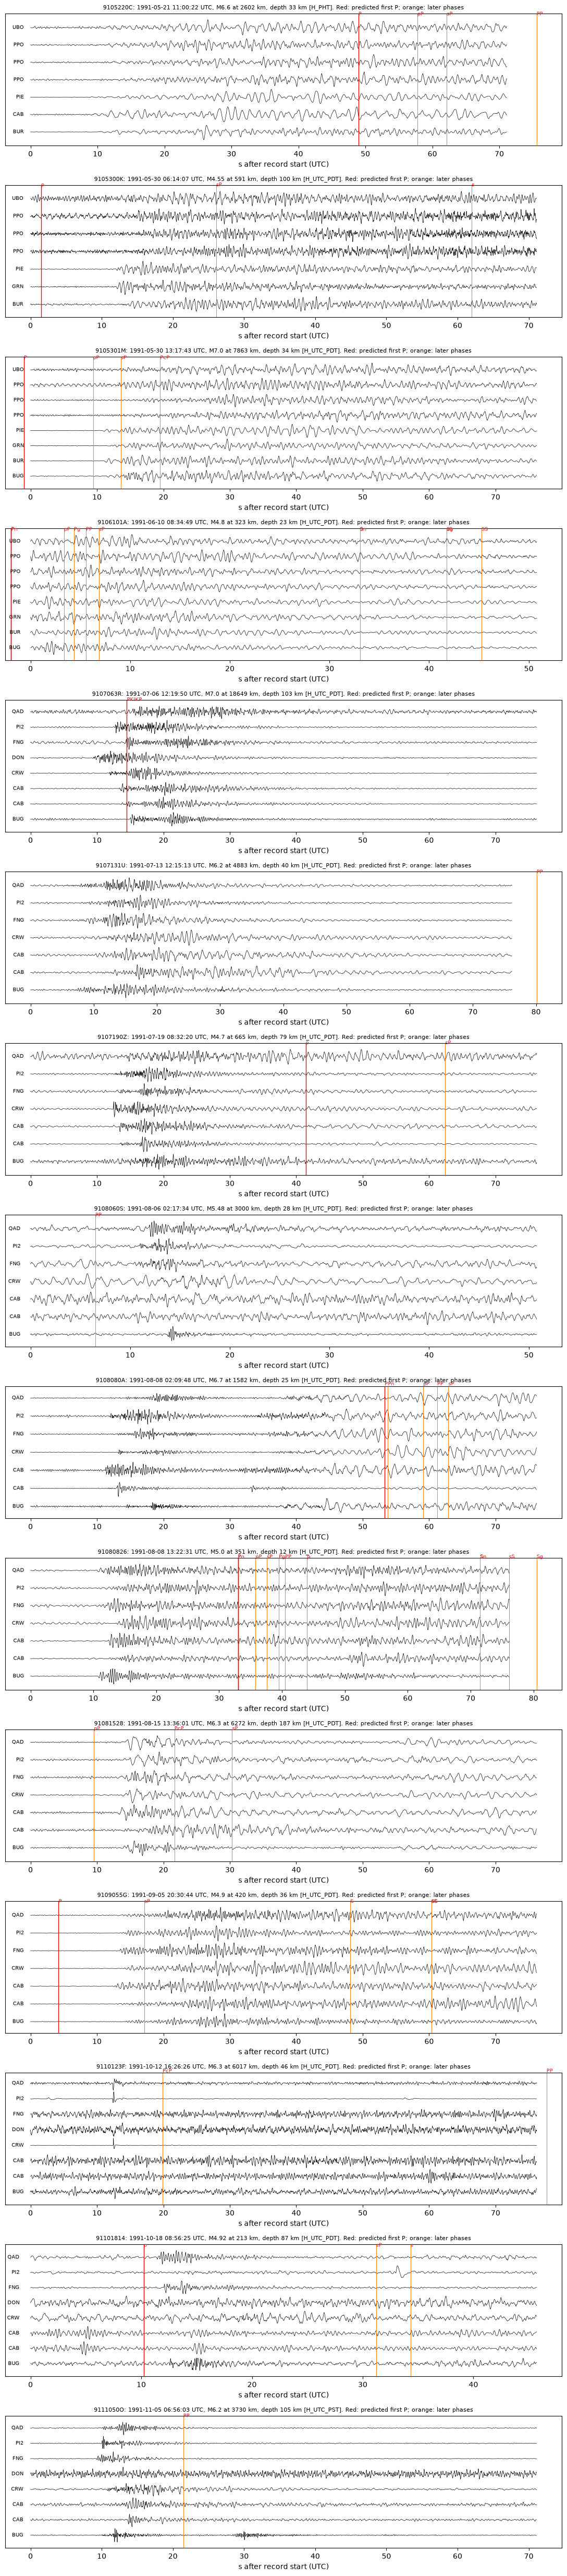

In [7]:
index = pd.read_csv(P['WAVEFORM_INDEX'], low_memory=False,
                    usecols=['event_id', 'wav_file', 'starttime', 'endtime', 'clock_regime'])
matches = match_records(cat[cat.dist_km > 100], index, SETTINGS['record_tolerance_s'])
matches.to_csv(OUT / 'waveform_matches.csv', index=False)
print(len(matches), 'record/event pairs;', matches.origin.nunique(), 'distinct events')
shown = matches[(matches.mag >= 4.5) & matches.predicted_p_in_record_s.between(-60, 75)].sort_values('origin')
display(shown)
fig = plot_records(shown, index, SETTINGS['plot_band_hz'], SETTINGS['reference'], OUT / 'candidate_records.png')
plt.show()

## 8. Analyst review

These judgements come from reviewing the plots above (19 November 2026). `onset_after_predicted_p_s` is the first clear arrival minus the predicted arrival of `reference_phase` (the first P unless stated). A positive value means the waveform times are late, i.e. the clock was fast by that amount, if the arrival is that phase of that event.


In [8]:
REVIEW = pd.DataFrame([
    dict(record='9105220C', verdict='teleseism', onset_after_predicted_p_s=-40,
         note='Looks teleseismic; onset about 40 s before the predicted P. Nothing arrives before P, so this is clock '
              'error, within the 60 s uncertainty before the 26 May reset (21–23 May carry "+1 min" annotations).'),
    dict(record='9105300K', verdict='probable regional', onset_after_predicted_p_s=12,
         note='Low frequency, little moveout between stations; clear first arrival 12–13 s after the predicted P. '
              'No depth phase is that early for this 100 km deep event (sP is at +25 s).'),
    dict(record='9105301M', verdict='probable teleseism', onset_after_predicted_p_s=12.5,
         note='Lowest frequency of the set, little moveout; clear first arrival 12–13 s after the predicted P. '
              'pP (+10 s) and sP (+15 s) bracket this, so a weak P followed by a depth phase is possible.'),
    dict(record='9108080A', verdict='local', onset_after_predicted_p_s=np.nan,
         note='Two local events: S−P about 4 s and about 5 s on BUG. Not a distant arrival.'),
    dict(record='9107063R', verdict='local', onset_after_predicted_p_s=np.nan,
         note='High frequency with about 5 s moveout across the network; not PKP.'),
    dict(record='91080826', verdict='regional', onset_after_predicted_p_s=-23,
         note='Medium frequency with about 1–2 s moveout across the network. The onset is 23 s before the predicted Pn; '
              'no phase arrives before Pn, so this is clock error if the arrival belongs to this event.'),
    dict(record='91081528', verdict='teleseism', onset_after_predicted_p_s=4, reference_phase='pP',
         note='Low frequency with about 1 s moveout across the network. The predicted P (−32.9 s) is before the record '
              'start; the onset is read 4 s after the first plotted phase, pP (+9.6 s), for this 187 km deep event. '
              'Measured from P it would be about +46 s; the analyst confirmed it is measured from pP.'),
    dict(record='9109055G', verdict='regional', onset_after_predicted_p_s=9,
         note='Low to medium frequency with about 1 s moveout across the network.'),
])
REVIEW['reference_phase'] = REVIEW.get('reference_phase', pd.Series(dtype=object)).fillna('P')
review = REVIEW.merge(matches.drop_duplicates('record'), on='record', how='left')
review.to_csv(OUT / 'analyst_review.csv', index=False)
display(review[['record', 'origin', 'mag', 'dist_km', 'depth_km', 'clock_regime', 'verdict', 'reference_phase',
                'onset_after_predicted_p_s', 'note']])
for r in review[review.onset_after_predicted_p_s.notna()].itertuples():
    print(f'\n{r.record}: phase times after the first P (the predicted P is {r.predicted_p_in_record_s:+.1f} s in the record)')
    display(phase_table(r, SETTINGS['reference']).set_index('phase').T)
anchors = review[review.onset_after_predicted_p_s.notna()].copy()
anchors['date'] = pd.to_datetime(anchors.origin).dt.strftime('%d %b')
print('\nApparent offsets (onset minus predicted phase; positive = waveform times late, clock fast):')
display(anchors[['date', 'record', 'clock_regime', 'verdict', 'reference_phase', 'onset_after_predicted_p_s']])


,record,origin,mag,dist_km,depth_km,clock_regime,verdict,reference_phase,onset_after_predicted_p_s,note
0,9105220C,1991-05-21 11:00:22.790000+00:00,6.60,2602.0,32.7378,H_PHT,teleseism,P,-40.0,Looks teleseismic; onset about 40 s before the...
1,9105300K,1991-05-30 06:14:07.230000+00:00,4.55,591.0,100.0000,H_UTC_PDT,probable regional,P,12.0,"Low frequency, little moveout between stations..."
2,9105301M,1991-05-30 13:17:43.700000+00:00,7.00,7863.0,33.5378,H_UTC_PDT,probable teleseism,P,12.5,"Lowest frequency of the set, little moveout; c..."
3,9108080A,1991-08-08 02:09:48.230000+00:00,6.70,1582.0,25.3780,H_UTC_PDT,local,P,NaN,Two local events: S−P about 4 s and about 5 s ...
4,9107063R,1991-07-06 12:19:50.300000+00:00,7.00,18649.0,102.6499,H_UTC_PDT,local,P,NaN,High frequency with about 5 s moveout across t...
5,91080826,1991-08-08 13:22:31.170000+00:00,5.00,351.0,11.7483,H_UTC_PDT,regional,P,-23.0,Medium frequency with about 1–2 s moveout acro...
6,91081528,1991-08-15 13:36:01.920000+00:00,6.30,6272.0,186.8928,H_UTC_PDT,teleseism,pP,4.0,Low frequency with about 1 s moveout across th...
7,9109055G,1991-09-05 20:30:44.170000+00:00,4.90,420.0,36.0000,H_UTC_PDT,regional,P,9.0,Low to medium frequency with about 1 s moveout...



9105220C: phase times after the first P (the predicted P is +49.0 s in the record)


phase,P,pP,sP,PP,PcP,S,sS,SS,ScS,surface 4.0 km/s,surface 3.5 km/s
after_first_p_s,0.0,8.8,13.2,26.6,225.2,251.5,267.5,289.6,667.1,344.3,437.3



9105300K: phase times after the first P (the predicted P is +1.5 s in the record)


phase,p,sP,s,PcP,ScS,surface 4.0 km/s,surface 3.5 km/s
after_first_p_s,0.0,24.6,60.5,421.9,836.7,70.8,91.9



9105301M: phase times after the first P (the predicted P is -1.0 s in the record)


... (5 outputs left out)


9109055G: phase times after the first P (the predicted P is +4.2 s in the record)


phase,P,sP,S,sS,SS,PcP,ScS,surface 4.0 km/s,surface 3.5 km/s
after_first_p_s,0.0,12.9,43.9,56.1,56.1,450.4,870.9,49.3,64.3



Apparent offsets (onset minus predicted phase; positive = waveform times late, clock fast):


,date,record,clock_regime,verdict,reference_phase,onset_after_predicted_p_s
0,21 May,9105220C,H_PHT,teleseism,P,-40.0
1,30 May,9105300K,H_UTC_PDT,probable regional,P,12.0
2,30 May,9105301M,H_UTC_PDT,probable teleseism,P,12.5
5,08 Aug,91080826,H_UTC_PDT,regional,P,-23.0
6,15 Aug,91081528,H_UTC_PDT,teleseism,pP,4.0
7,05 Sep,9109055G,H_UTC_PDT,regional,P,9.0


## 9. Conclusions

- **HYPO71** has no regional or distant events: all 8,233 origins lie within 49 km of Pinatubo.
- **Pinatubo's own M 4–6 earthquakes** in ISC and USGS fall mostly on 15–17 June, when HYPO71 has no locations. After the reset, the nearest HYPO71 origins differ from the catalogue by tens of seconds. That rules out minute- and hour-level errors after the UTC rules, but cannot measure seconds.
- **Long S−P pick groups** are not in the global catalogues, and **1-minute SSAM** shows nothing at any distant arrival, so neither can anchor the clock.
- **Triggered records** give the anchors. Of 13 records reviewed, 8 show a distant arrival; the apparent offsets (onset minus predicted arrival, positive = waveform times late) are:

| Date (1991) | Record | Event | Apparent offset | Clock rule |
|---|---|---|---|---|
| 21 May | 9105220C | M 6.6, 2,602 km | −40 s | before the reset (60 s nominal) |
| 30 May | 9105300K | M 4.6, 591 km | +12 s | after the reset |
| 30 May | 9105301M | M 7.0, 7,863 km | +12.5 s (or a depth phase) | after the reset |
| 8 Aug | 91080826 | M 5.0, 351 km | −23 s | after the reset |
| 15 Aug | 91081528 | M 6.3, 6,272 km, 187 km deep | +4 s relative to pP | after the reset |
| 5 Sep | 9109055G | M 4.9, 420 km | +9 s | after the reset |

- After the reset the offsets range from −23 to +12 s and change sign between days. That fits a clock that drifted by about 2 s a day and was reset only now and then, not one systematic error, so **no correction is applied**.
- The nominal uncertainty after the reset was 5 s (MDETECT's "about 2 seconds per day" with daily reboots), and four of five anchors exceed it. It is now **25 s** in `clock_regimes.csv` (19 November), which matches these checks. Before the reset, the −40 s anchor fits the 60 s assumed.
- Each anchor rests on one event and one record, and a nearby local event could mimic an arrival. More anchors, especially on days with two events, would tighten the bound.
